# Effect of helical displacement on the density power spectrum

**Question:** how does the point-catalogue $P(k)$ change relative to the original Gaussian field when we add the helical displacement?

## 1. Three stages, matched by initial condition

1. **Original Gaussian field:** $P_{\rm input}(k)$, measured from the saved density mesh $\delta(\mathbf q)$.
2. **ZA-only particles:** $\mathbf x_{\rm ZA}=\mathbf q+\boldsymbol\Psi_{\rm ZA}(\mathbf q)$, giving $P_{\rm ZA}(k)$.
3. **ZA + helical displacement:** $\mathbf x_{\rm ZA+hel}=\mathbf q+\boldsymbol\Psi_{\rm ZA}(\mathbf q)+\boldsymbol\Psi_{\rm hel}(\mathbf q)$, giving $P_{\rm ZA+hel}(k)$.

Positions are periodic. Each comparison uses the **same Gaussian field and initial particle lattice**. The no-helical-displacement baseline has $A=0$; the $\epsilon=0$ case below still has displacement strength $A=16$ and equal expected power in the two handed components.

Keep **5 realizations per helicity**: seeds 1000–1004 for $\epsilon=-1,0,+1$; seeds 1050–1054 for $\epsilon=-0.5,+0.5$. Use $L=1000\ h^{-1}\mathrm{Mpc}$, a $256^3$ initial density mesh, $32^3$ particles, and $A=16\ h^{-1}\mathrm{Mpc}$. All particles are used.


In [1]:
from pathlib import Path
import importlib.util
from IPython.display import display, Markdown
%matplotlib inline
import matplotlib.pyplot as plt
OUT = Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261123_catalogue_power_matched_baseline_five_each')
spec = importlib.util.spec_from_file_location('matched_power_report', Path('/srv/beegfs/scratch/users/h/hes/projects/cosmicPV/20261123_catalogue_power_matched_baseline_five_each/code/src/parity_study/tests/catalogue_power_baseline.py'))
report = importlib.util.module_from_spec(spec)
spec.loader.exec_module(report)


## 2. Original and displaced density power

For both meshes and particles, $P(k)=L^3\langle|\delta_{\mathbf k}|^2\rangle$ in each Fourier shell. The mesh uses normalized Fourier coefficients; particles use $\delta_{\mathbf k}=N_p^{-1}\sum_j e^{-i\mathbf k\cdot\mathbf x_j}$ for nonzero modes. Thus the spectra have the same units and normalization.

The black curves use the **actual matched initial conditions**. The dotted grey line is the analytic ensemble input spectrum. Coloured lines show the mean of five final-catalogue spectra; shading is **SEM** (sample standard deviation divided by $\sqrt{5}$).

Only complete shells inside the input band $k\le0.10053\ h\,\mathrm{Mpc}^{-1}$ are plotted, with width $2\pi/L$. The final partial shell at the cutoff is included in the broad-band table below. No Poisson shot-noise subtraction is applied to these displaced-lattice catalogues.


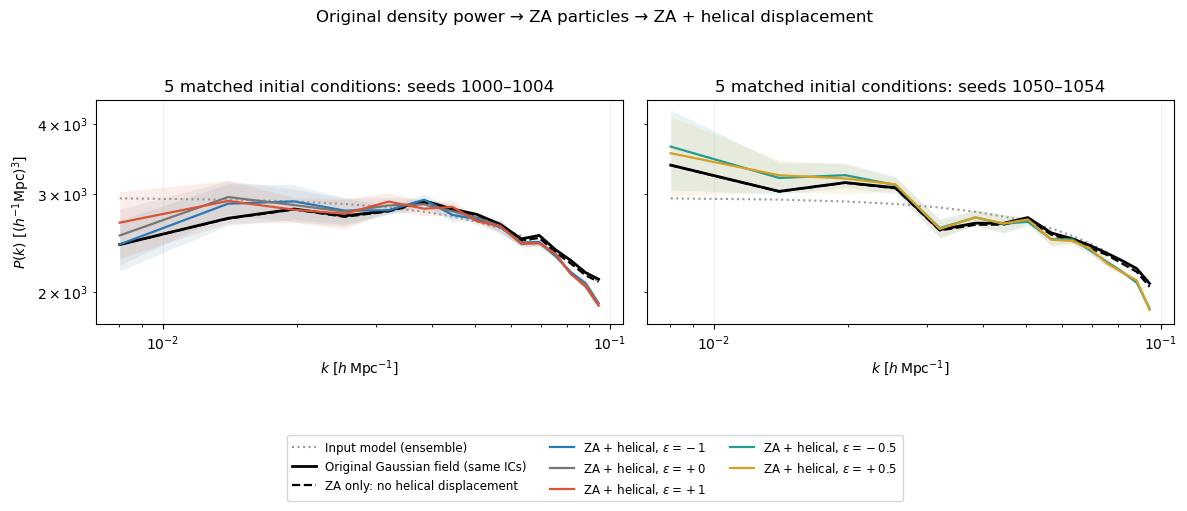

In [2]:
fig = report.spectra_figure(OUT)
display(fig)
plt.close(fig)

## 3. How much does adding the helical field change $P(k)$?

For each matched realization $s$, define
$$R_{{\rm total},s}(k)=\frac{P_{{\rm ZA+hel},s}(k)}{P_{{\rm input},s}(k)}-1,\qquad
R_{{\rm hel},s}(k)=\frac{P_{{\rm ZA+hel},s}(k)}{P_{{\rm ZA},s}(k)}-1.$$

The left panel measures the total change from the original field. The right panel isolates the effect of adding the helical displacement to the ZA catalogue. Zero means unchanged power; positive/negative values mean enhancement/suppression. Form ratios **within each IC first**, then plot their mean and SEM across five ICs.


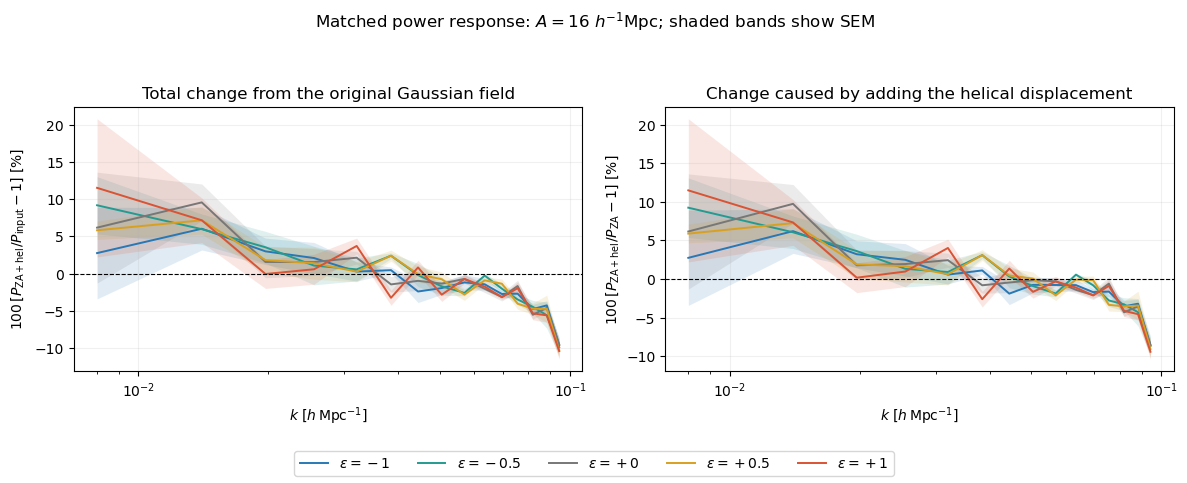

In [3]:
fig = report.response_figure(OUT)
display(fig)
plt.close(fig)

## 4. Summary over the input Fourier band

First average power over all nonzero modes with $k\le0.10053\ h\,\mathrm{Mpc}^{-1}$ within each realization, then form the two matched ratios. The table gives the mean percentage change ± SEM over five realizations.


In [4]:
display(Markdown(report.summary_table(OUT)))

| ε | Change from original field | Change from ZA-only catalogue |
|---:|---:|---:|
| -1 | -4.898% ± 0.212% | -3.920% ± 0.242% |
| -0.5 | -5.169% ± 0.163% | -4.221% ± 0.137% |
| +0 | -4.807% ± 0.151% | -3.828% ± 0.165% |
| +0.5 | -5.149% ± 0.185% | -4.201% ± 0.158% |
| +1 | -5.035% ± 0.150% | -4.059% ± 0.153% |

The helical displacement is transverse, so $-\nabla\cdot\boldsymbol\Psi_{\rm hel}=0$: it does not change density at first order. The full particle map can change density power through higher-order terms. A power change relative to the original field measures this density response; the sign of parity violation is tested separately with chirality.

Ratios to the input field are restricted to its supported Fourier band. The earlier spectra at higher $k$ contain prominent particle-lattice structure and remain saved in the previous report.


[Matched spectra and ratios](saved/20261123_catalogue_power_matched_baseline_five_each/matched_power.csv) · [Band summary](saved/20261123_catalogue_power_matched_baseline_five_each/band_summary.csv) · [All arrays](saved/20261123_catalogue_power_matched_baseline_five_each/comparison.npz) · [Plots](saved/20261123_catalogue_power_matched_baseline_five_each/figures/) · [Configuration](saved/20261123_catalogue_power_matched_baseline_five_each/config.json) · [Validation](saved/20261123_catalogue_power_matched_baseline_five_each/validation/baselines.json) · [Previous report](saved/20261123_catalogue_power_matched_baseline_five_each/before/field_PVdisp_Pk.ipynb)